In [1]:
import numpy as np
import pandas as pd


In [2]:
data = {
    "study_hours": [
        1, 2, 1.5, 2.5,
        3, 4, 3.5, 4.5,
        5, 6, 5.5, 6.5
    ],
    "result": [
        "Fail", "Fail", "Fail", "Fail",
        "Pass", "Pass", "Pass", "Pass",
        "Good", "Good", "Good", "Good"
    ]
}


In [3]:
df = pd.DataFrame(data)

In [4]:
df


,study_hours,result
0,1.0,Fail
1,2.0,Fail
2,1.5,Fail
3,2.5,Fail
4,3.0,Pass
5,4.0,Pass
6,3.5,Pass
7,4.5,Pass
8,5.0,Good
9,6.0,Good


In [5]:
df["result"] = df["result"].map({
    "Fail": 0,
    "Pass": 1,
    "Good": 2
})

df

,study_hours,result
0,1.0,0
1,2.0,0
2,1.5,0
3,2.5,0
4,3.0,1
5,4.0,1
6,3.5,1
7,4.5,1
8,5.0,2
9,6.0,2


In [6]:
X = df[["study_hours"]].values
y = df["result"].values

print(X.shape)
print(y.shape)

(12, 1)
(12,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (9, 1)
X_test: (3, 1)
y_train: (9,)
y_test: (3,)


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(1,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 8)                   │              16 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │              27 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 43 (172.00 B)

 Trainable params: 43 (172.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=3,
    verbose=1
)

Epoch 1/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 51ms/step - accuracy: 0.3333 - loss: 1.1619
Epoch 2/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.3333 - loss: 1.1538
Epoch 3/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3333 - loss: 1.1461
Epoch 4/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.3333 - loss: 1.1385 
Epoch 5/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.3333 - loss: 1.1310 
Epoch 6/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3333 - loss: 1.1237
Epoch 7/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.3333 - loss: 1.1166 
Epoch 8/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3333 - loss: 1.1097 
Epoch 9/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.3333 - loss: 1.1028 
Epoch 10/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.3333 - loss: 1.0961 
Epoch 11/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.3333 - loss: 1.0894 
Epoch 12/100
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.33

In [12]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.718600332736969
Test Accuracy: 0.6666666865348816


In [13]:
new_student = scaler.transform([[4]])

probabilities = model.predict(new_student, verbose=0)

print("Probabilities:", probabilities)
print("Predicted class:", np.argmax(probabilities))

Probabilities: [[0.32024035 0.32800233 0.35175732]]
Predicted class: 2


In [14]:
probabilities = model.predict(X_test, verbose=0)

predictions = np.argmax(probabilities, axis=1)

print("Actual classes:   ", y_test)
print("Predicted classes:", predictions)
print("Probabilities:\n", probabilities)

Actual classes:    [2 1 0]
Predicted classes: [2 0 0]
Probabilities:
 [[0.2355354  0.2311099  0.5333547 ]
 [0.410335   0.32690567 0.2627593 ]
 [0.6642152  0.12910514 0.20667964]]


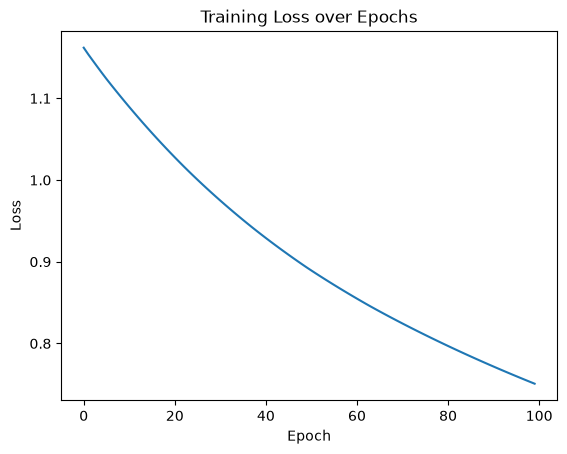

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.show()